# ChargeTime AI: Predicting Electric Vehicle Charging Session Duration Using Machine Learning[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)**Course:** Foundations of AIML (B.Tech CSE Third-Year Mini Project)  **Author:** Sarthak Kharche  **Dataset:** EV Charging Patterns Dataset (Kaggle: `valakhorasani/electric-vehicle-charging-patterns`)  **Primary Algorithm:** Linear Regression (`sklearn.linear_model.LinearRegression`)

### 🚀 Google Colab Environment SetupIf running this notebook inside **Google Colab**, execute the cell below to install required packages and verify the dataset path.

In [1]:
import sys
# Check if running in Google Colab
if 'google.colab' in sys.modules:
    print("Detected Google Colab environment. Installing requirements...")
    !pip install -q pandas numpy scikit-learn matplotlib seaborn joblib
    print("Dependencies installed successfully!")
else:
    print("Running in local Python environment.")

Running in local Python environment.


## 2. Problem StatementAs electric vehicles (EVs) become increasingly ubiquitous, efficient management of charging station infrastructure and user scheduling requires accurate forecasting of charging session durations. Session durations vary significantly based on vehicle specifications (battery capacity, state of charge), charging infrastructure (charging rate, charger type), environmental factors (temperature), and driver usage patterns.Without predictive duration estimates, EV owners experience uncertainty in planning their schedules, and station operators face challenges in optimizing charger utilization. This project addresses the problem by constructing a supervised machine learning regression model to predict **Charging Duration (hours)** using historical session data.

## 3. ObjectiveThe primary objectives of this mini project are:1. **Data Exploration & Inspection**: Load, inspect, and analyze the EV Charging Patterns dataset (~1,320 session records).2. **Exploratory Data Analysis (EDA)**: Understand feature distributions, relationships with charging duration, and correlation structure.3. **Data Preprocessing**: Design a robust scikit-learn `ColumnTransformer` pipeline using `StandardScaler` for numerical features and `OneHotEncoder` for categorical variables.4. **Supervised Regression Modeling**: Train a **Linear Regression** model as the primary supervised learning algorithm (avoiding black-box algorithms to emphasize foundational ML principles).5. **Model Evaluation & Diagnostics**: Evaluate performance using MAE, MSE, RMSE, and R² Score, compare against a Mean Baseline model, and perform residual diagnostics.6. **Interpretability**: Analyze learned regression coefficients to understand feature associations.7. **Deployment Readiness**: Save the preprocessing pipeline and trained model for integration into a Streamlit web application.

## 4. Dataset InformationThe dataset is sourced from Kaggle's **Electric Vehicle Charging Patterns** dataset:- **Total Records**: ~1,320 EV charging sessions.- **Features**: Includes vehicle attributes, charging station details, battery state of charge (Start/End %), energy consumed, charging rates, temperature, user types, and timestamps.- **Target Variable**: `Charging Duration (hours)` (Continuous Numerical Target).

## 5. Import Libraries

In [2]:
import pathlib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette("crest")
print("Libraries successfully imported!")

Libraries successfully imported!


## 6. Load Dataset

In [3]:
# Define dataset path platform-independently
DATA_PATH = pathlib.Path("../data/raw/ev_charging_patterns.csv")

if not DATA_PATH.exists():
    # Try current directory path if running directly in notebooks folder
    DATA_PATH = pathlib.Path("data/raw/ev_charging_patterns.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset file not found. Please ensure ev_charging_patterns.csv is placed in data/raw/")

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Shape: {df_raw.shape}")
df_raw.head()

Dataset successfully loaded. Shape: (1320, 20)


,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,13.036239,Evening,Saturday,83.120003,99.624328,199.577785,38.316313,1.0,Level 1,Long-Distance Traveler
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,10.161471,Morning,Saturday,54.258950,63.743786,203.661847,-7.834199,1.0,Level 1,Long-Distance Traveler


## 7. Dataset InspectionBefore building the ML pipeline, we inspect the exact columns, data types, missing values, duplicates, and statistical distributions to avoid making blind assumptions.

In [4]:
print("=== DATASET OVERVIEW ===")
print(f"Number of Rows    : {df_raw.shape[0]}")
print(f"Number of Columns : {df_raw.shape[1]}\n")

print("=== DATA TYPES & MISSING VALUES ===")
inspection_df = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Missing Values": df_raw.isnull().sum(),
    "Missing (%)": (df_raw.isnull().sum() / len(df_raw)) * 100,
    "Unique Values": df_raw.nunique()
})
print(inspection_df)

print(f"\nDuplicate Records Count: {df_raw.duplicated().sum()}")

=== DATASET OVERVIEW ===
Number of Rows    : 1320
Number of Columns : 20

=== DATA TYPES & MISSING VALUES ===
                                         Data Type  Missing Values  \
User ID                                     object               0   
Vehicle Model                               object               0   
Battery Capacity (kWh)                     float64               0   
Charging Station ID                         object               0   
Charging Station Location                   object               0   
Charging Start Time                         object               0   
Charging End Time                           object               0   
Energy Consumed (kWh)                      float64              66   
Charging Duration (hours)                  float64               0   
Charging Rate (kW)                         float64              66   
Charging Cost (USD)                        float64               0   
Time of Day                                 object

In [5]:
print("=== UNIQUE VALUES FOR CATEGORICAL COLUMNS ===")
cat_cols = df_raw.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"• {col} ({df_raw[col].nunique()} unique): {df_raw[col].unique()[:8]}")

print("\n=== DESCRIPTIVE STATISTICAL SUMMARY ===")
df_raw.describe()

=== UNIQUE VALUES FOR CATEGORICAL COLUMNS ===
• User ID (1320 unique): ['User_1' 'User_2' 'User_3' 'User_4' 'User_5' 'User_6' 'User_7' 'User_8']
• Vehicle Model (5 unique): ['BMW i3' 'Hyundai Kona' 'Chevy Bolt' 'Nissan Leaf' 'Tesla Model 3']
• Charging Station ID (462 unique): ['Station_391' 'Station_428' 'Station_181' 'Station_327' 'Station_108'
 'Station_335' 'Station_162' 'Station_302']
• Charging Station Location (5 unique): ['Houston' 'San Francisco' 'Los Angeles' 'Chicago' 'New York']
• Charging Start Time (1320 unique): ['2024-01-01 00:00:00' '2024-01-01 01:00:00' '2024-01-01 02:00:00'
 '2024-01-01 03:00:00' '2024-01-01 04:00:00' '2024-01-01 05:00:00'
 '2024-01-01 06:00:00' '2024-01-01 07:00:00']
• Charging End Time (1309 unique): ['2024-01-01 00:39:00' '2024-01-01 03:01:00' '2024-01-01 04:48:00'
 '2024-01-01 06:42:00' '2024-01-01 05:46:00' '2024-01-01 07:10:00'
 '2024-01-01 07:53:00' '2024-01-01 10:42:00']
• Time of Day (4 unique): ['Evening' 'Morning' 'Afternoon' 'Night']
• Da

,Battery Capacity (kWh),Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years)
count,1320.000000,1254.000000,1320.000000,1254.000000,1320.000000,1320.000000,1320.000000,1254.000000,1320.000000,1320.000000
mean,74.534692,42.642894,2.269377,25.963003,22.551352,49.130012,75.141590,153.596788,15.263591,3.612843
std,20.626914,22.411705,1.061037,14.011326,10.751494,24.074134,17.080580,86.004987,14.831216,2.309824
min,1.532807,0.045772,0.095314,1.472549,0.234317,2.325959,7.604224,0.862361,-10.724770,0.000000
25%,62.000000,23.881193,1.397623,13.856583,13.368141,27.786903,62.053266,79.445335,2.800664,2.000000
50%,75.000000,42.691405,2.258136,25.603799,22.076360,48.241771,75.682496,152.259867,14.630846,4.000000
75%,85.000000,61.206218,3.112806,37.502998,31.646044,69.277921,88.201370,226.073284,27.981810,6.000000
max,193.003074,152.238758,7.635145,97.342255,69.407743,152.489761,177.708666,398.364775,73.169588,11.688592


## 8. Data CleaningWe handle duplicates, strip leading/trailing whitespaces from categorical strings, and handle any potential missing values.

In [6]:
# Make a copy for cleaning
df_clean = df_raw.copy()

# Drop duplicates if present
df_clean = df_clean.drop_duplicates()

# Clean categorical string columns
for col in cat_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Missing value handling (median for numeric, mode for categorical)
num_cols = df_clean.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Cleaned dataset shape: {df_clean.shape}")

Cleaned dataset shape: (1320, 20)


## 9. Exploratory Data Analysis (EDA)We explore target distribution, relationships between key numerical features and charging duration, correlation structure, and categorical grouping patterns.

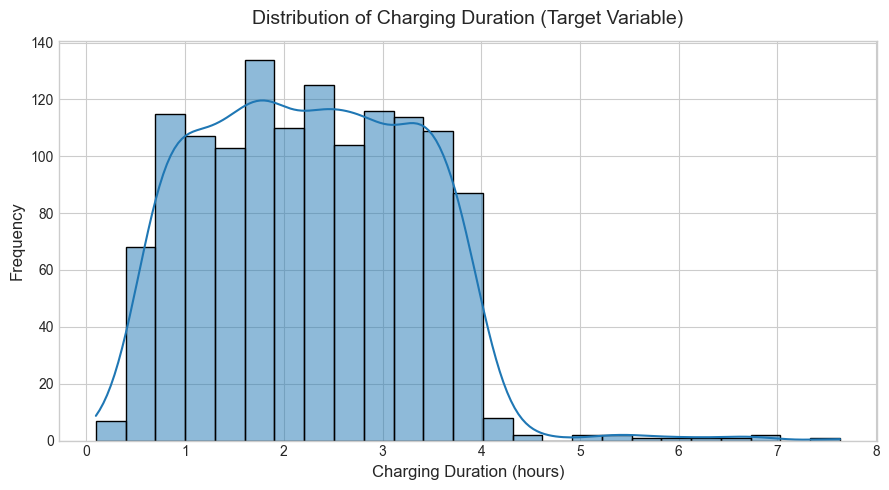

In [7]:
TARGET_COL = "Charging Duration (hours)"

# Distribution of Target Variable
plt.figure(figsize=(9, 5))
sns.histplot(df_clean[TARGET_COL], kde=True, color="#1f77b4", bins=25)
plt.title("Distribution of Charging Duration (Target Variable)", fontsize=14, pad=12)
plt.xlabel("Charging Duration (hours)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

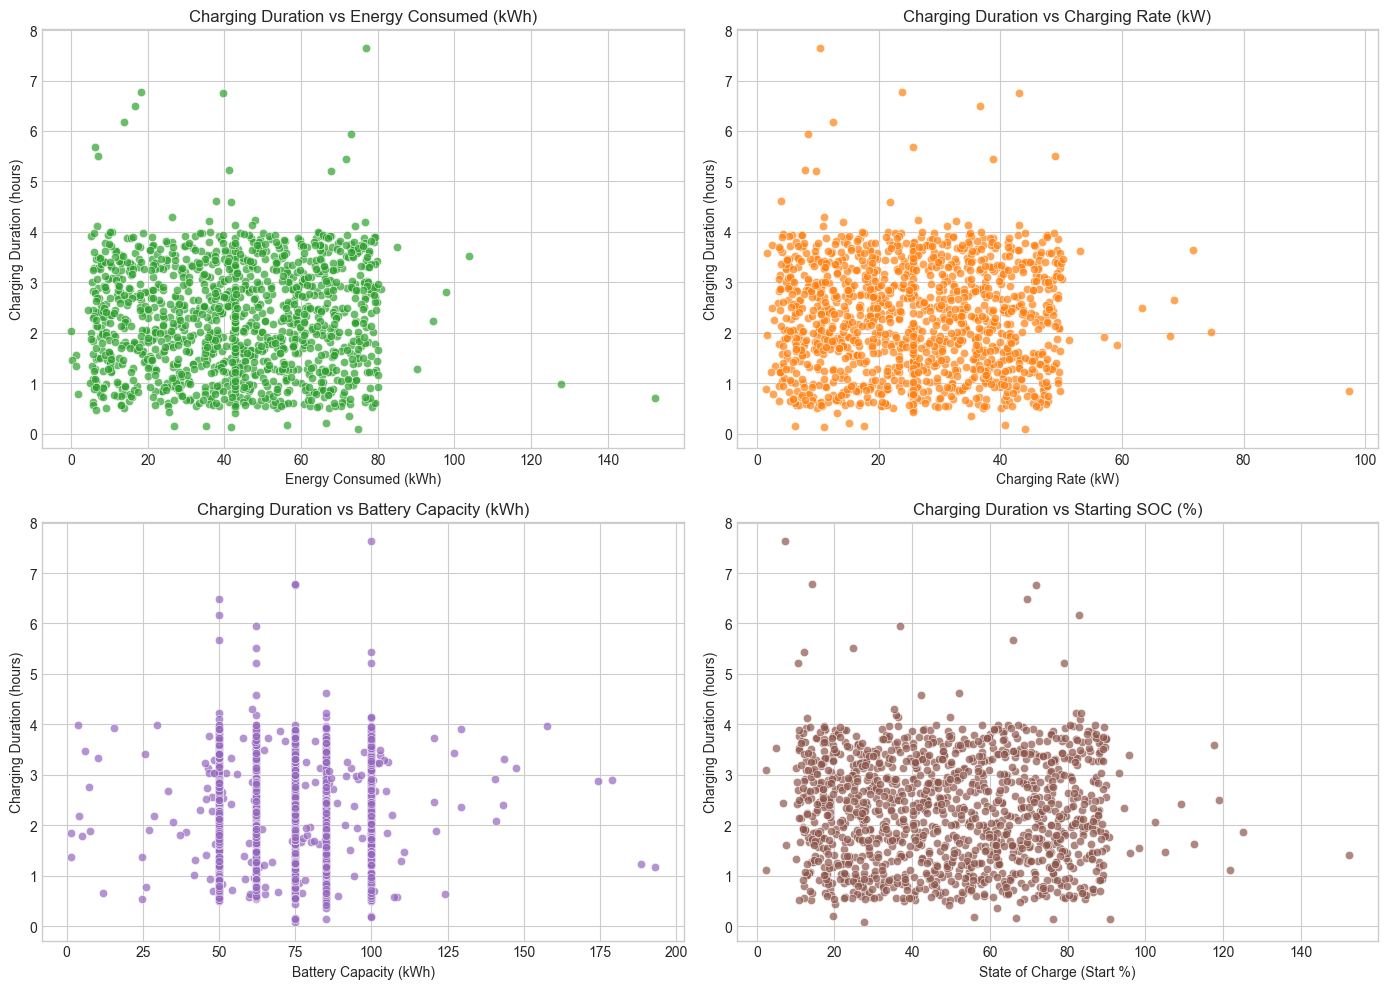

In [8]:
# Key Feature Scatter Plots against Target
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=df_clean, x="Energy Consumed (kWh)", y=TARGET_COL, ax=axes[0,0], alpha=0.7, color="#2ca02c")
axes[0,0].set_title("Charging Duration vs Energy Consumed (kWh)")

sns.scatterplot(data=df_clean, x="Charging Rate (kW)", y=TARGET_COL, ax=axes[0,1], alpha=0.7, color="#ff7f0e")
axes[0,1].set_title("Charging Duration vs Charging Rate (kW)")

sns.scatterplot(data=df_clean, x="Battery Capacity (kWh)", y=TARGET_COL, ax=axes[1,0], alpha=0.7, color="#9467bd")
axes[1,0].set_title("Charging Duration vs Battery Capacity (kWh)")

sns.scatterplot(data=df_clean, x="State of Charge (Start %)", y=TARGET_COL, ax=axes[1,1], alpha=0.7, color="#8c564b")
axes[1,1].set_title("Charging Duration vs Starting SOC (%)")

plt.tight_layout()
plt.show()

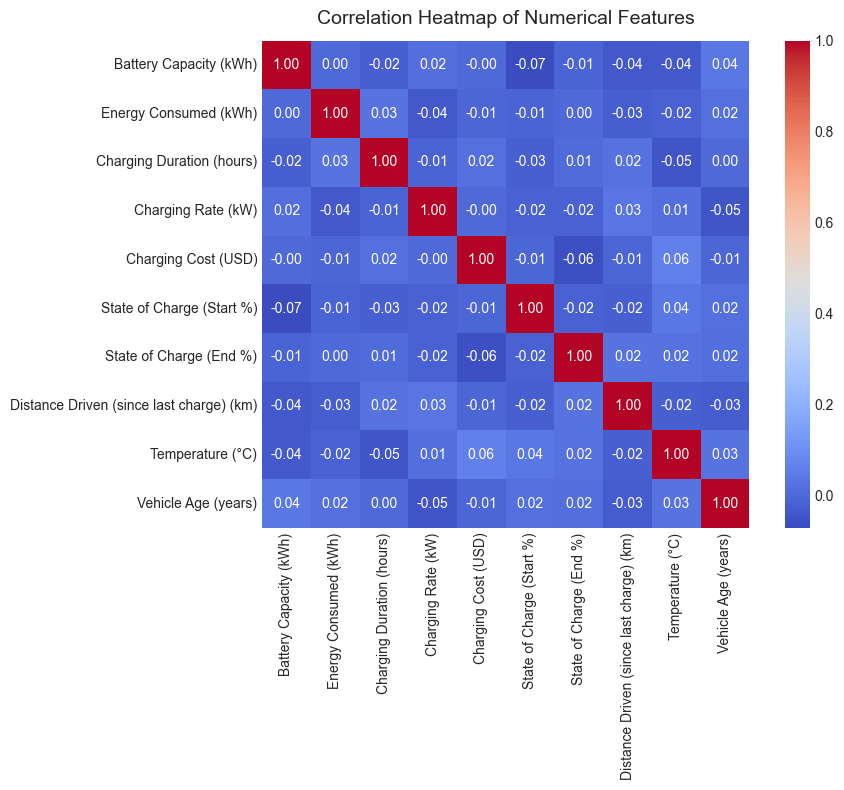

In [9]:
# Correlation Heatmap for Numerical Features
plt.figure(figsize=(10, 8))
numeric_df = df_clean.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

C:\Users\sarth\AppData\Local\Temp\ipykernel_14124\3265566930.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Charger Type", y=TARGET_COL, ax=axes[0], palette="Blues")
C:\Users\sarth\AppData\Local\Temp\ipykernel_14124\3265566930.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="User Type", y=TARGET_COL, ax=axes[1], palette="Greens")
C:\Users\sarth\AppData\Local\Temp\ipykernel_14124\3265566930.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Time of Day", y=TARGET_COL, ax=axes[2],

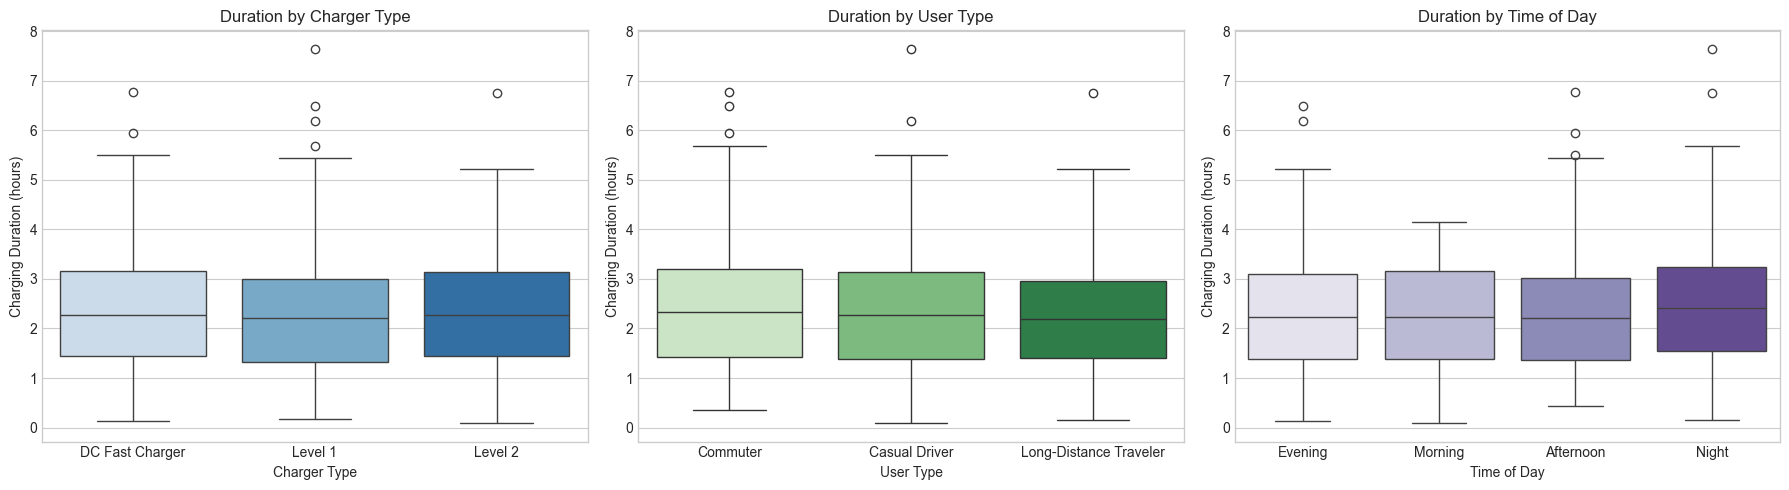

In [10]:
# Categorical Feature Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_clean, x="Charger Type", y=TARGET_COL, ax=axes[0], palette="Blues")
axes[0].set_title("Duration by Charger Type")

sns.boxplot(data=df_clean, x="User Type", y=TARGET_COL, ax=axes[1], palette="Greens")
axes[1].set_title("Duration by User Type")

sns.boxplot(data=df_clean, x="Time of Day", y=TARGET_COL, ax=axes[2], palette="Purples")
axes[2].set_title("Duration by Time of Day")

plt.tight_layout()
plt.show()

## 10. Feature Selection & Target Leakage Audit### Target Column`Charging Duration (hours)` is set strictly as target vector y.### Included Predictor Features (X)1. **Numerical Features (8):**   - `Battery Capacity (kWh)`: Physical energy storage capacity of EV.   - `Energy Consumed (kWh)`: Total energy transferred into battery during session.   - `Charging Rate (kW)`: Power delivery rate of charging station.   - `State of Charge (Start %)`: Initial battery charge level.   - `State of Charge (End %)`: Target battery charge level upon completion.   - `Distance Driven (since last charge) (km)`: Usage intensity indicator.   - `Temperature (°C)`: Ambient temperature impacting battery chemistry and thermal management.   - `Vehicle Age (years)`: Age of EV impacting battery degradation.2. **Categorical Features (5):**   - `Vehicle Model`: Car model specification (e.g. Tesla Model 3, BMW i3).   - `Charger Type`: Infrastructure level (Level 1, Level 2, DC Fast Charger).   - `Time of Day`: Morning, Afternoon, Evening, Night.   - `Day of Week`: Day session occurred.   - `User Type`: Driver behavior profile (Commuter, Casual Driver, Long-Distance Traveler).### Excluded / Dropped Features & Rationale- `User ID`, `Charging Station ID`, `Charging Station Location`: Arbitrary identifiers/metadata with no direct generalization.- `Charging Start Time`, `Charging End Time`: **Direct Target Leakage!** `Charging End Time - Charging Start Time` mathematically calculates exact duration. Using `Charging End Time` as an input would render the model trivial and useless for pre-session prediction.- `Charging Cost (USD)`: Post-session outcome derived from energy and time.

In [11]:
NUMERICAL_FEATURES = [
    "Battery Capacity (kWh)",
    "Energy Consumed (kWh)",
    "Charging Rate (kW)",
    "State of Charge (Start %)",
    "State of Charge (End %)",
    "Distance Driven (since last charge) (km)",
    "Temperature (°C)",
    "Vehicle Age (years)"
]

CATEGORICAL_FEATURES = [
    "Vehicle Model",
    "Charger Type",
    "Time of Day",
    "Day of Week",
    "User Type"
]

X = df_clean[NUMERICAL_FEATURES + CATEGORICAL_FEATURES].copy()
y = df_clean[TARGET_COL].copy()

print(f"Predictor Matrix X shape: {X.shape}")
print(f"Target Vector y shape   : {y.shape}")

Predictor Matrix X shape: (1320, 13)
Target Vector y shape   : (1320,)


## 11. Data Preprocessing PipelineWe build a scikit-learn `ColumnTransformer` to handle preprocessing:- `StandardScaler()` for scaling numerical features to zero mean and unit variance.- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` for nominal categorical variables to prevent creating arbitrary ordinal numbers (e.g., avoiding AC=1, DC=2).

In [12]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, NUMERICAL_FEATURES),
        ("cat", cat_transformer, CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)
print("Preprocessing ColumnTransformer constructed successfully.")

Preprocessing ColumnTransformer constructed successfully.


## 12. Train-Test SplitWe partition the dataset into **80% Training Set** and **20% Testing Set** using `random_state=42` for strict reproducibility.Crucially, the preprocessing pipeline is fitted **only on the training set** (`X_train`) to prevent **data leakage**.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit preprocessor on X_train ONLY, then transform both X_train and X_test
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Extract encoded feature names
encoded_feature_names = []
for name, trans, cols in preprocessor.transformers_:
    if name == "num":
        encoded_feature_names.extend(cols)
    elif name == "cat":
        encoded_feature_names.extend(trans.get_feature_names_out(cols))

print(f"Training set: X_train shape = {X_train.shape} -> Transformed = {X_train_transformed.shape}")
print(f"Testing set : X_test shape  = {X_test.shape} -> Transformed = {X_test_transformed.shape}")
print(f"Total post-encoding features: {len(encoded_feature_names)}")

Training set: X_train shape = (1056, 13) -> Transformed = (1056, 30)
Testing set : X_test shape  = (264, 13) -> Transformed = (264, 30)
Total post-encoding features: 30


## 13. Linear Regression ModelWe instantiate the primary supervised machine learning algorithm: **Linear Regression** (`sklearn.linear_model.LinearRegression`).The mathematical formulation is:y_hat = beta_0 + beta_1 * x_1 + beta_2 * x_2 + ... + beta_p * x_pwhere beta_0 is the intercept and beta_1, ..., beta_p are the regression coefficients learned via Ordinary Least Squares (OLS) minimization.

In [14]:
model = LinearRegression()
print("Linear Regression model initialized.")

Linear Regression model initialized.


## 14. Model Training & Baseline Training

In [15]:
# Train Linear Regression model
model.fit(X_train_transformed, y_train)
print(f"Linear Regression training completed.")
print(f"Learned Intercept (beta_0): {model.intercept_:.4f}")

# Train Mean Baseline Model for comparison (Prompt requirement 12)
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train_transformed, y_train)
print(f"Mean Baseline training completed. Mean target value: {baseline_model.constant_[0][0]:.4f} hours")

Linear Regression training completed.
Learned Intercept (beta_0): 2.2728
Mean Baseline training completed. Mean target value: 2.2690 hours


## 15. Predictions on Test Dataset

In [16]:
y_pred_lr = model.predict(X_test_transformed)
y_pred_base = baseline_model.predict(X_test_transformed)

df_predictions = pd.DataFrame({
    "Actual Duration (hrs)": y_test.values,
    "Linear Regression Pred": y_pred_lr,
    "Mean Baseline Pred": y_pred_base,
    "LR Residual (Actual - Pred)": y_test.values - y_pred_lr
})
df_predictions.head(10)

,Actual Duration (hrs),Linear Regression Pred,Mean Baseline Pred,LR Residual (Actual - Pred)
0,1.497563,2.186124,2.269003,-0.688561
1,1.551271,2.276349,2.269003,-0.725077
2,2.710437,2.505659,2.269003,0.204778
3,2.209543,2.130489,2.269003,0.079054
4,2.768766,2.106878,2.269003,0.661888
5,2.104491,2.248565,2.269003,-0.144074
6,2.014010,2.537017,2.269003,-0.523007
7,2.914258,2.266236,2.269003,0.648022
8,1.028819,2.243909,2.269003,-1.215090
9,1.666890,2.015247,2.269003,-0.348357


## 16. Model EvaluationWe evaluate model accuracy on the unseen 20% test dataset using four standard regression metrics:- **MAE (Mean Absolute Error)**- **MSE (Mean Squared Error)**- **RMSE (Root Mean Squared Error)**- **R² Score (Coefficient of Determination)**

In [17]:
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

lr_mae, lr_mse, lr_rmse, lr_r2 = compute_metrics(y_test, y_pred_lr)
base_mae, base_mse, base_rmse, base_r2 = compute_metrics(y_test, y_pred_base)

metrics_summary = pd.DataFrame({
    "Metric": ["MAE (hours)", "MSE", "RMSE (hours)", "R² Score"],
    "Linear Regression": [lr_mae, lr_mse, lr_rmse, lr_r2],
    "Mean Baseline": [base_mae, base_mse, base_rmse, base_r2]
})
print("=== MODEL PERFORMANCE COMPARISON ===")
print(metrics_summary.to_string(index=False))

=== MODEL PERFORMANCE COMPARISON ===
      Metric  Linear Regression  Mean Baseline
 MAE (hours)           0.872244       0.857858
         MSE           1.207235       1.156494
RMSE (hours)           1.098742       1.075404
    R² Score          -0.043877      -0.000003


## 17. Actual vs Predicted VisualizationWe plot Actual Charging Duration vs Predicted Charging Duration on the test set alongside an ideal perfect fit diagonal line (Y = X).

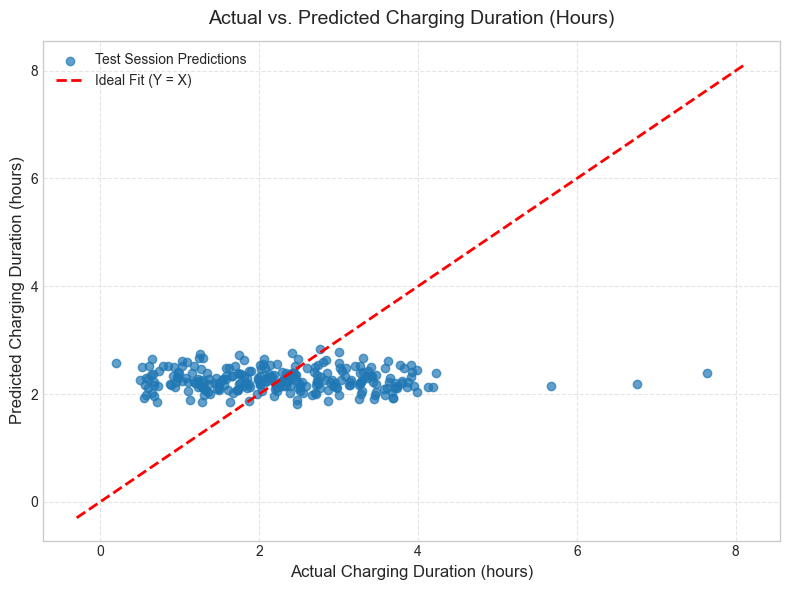

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.7, color="#1f77b4", label="Test Session Predictions")
max_val = max(max(y_test), max(y_pred_lr)) + 0.5
min_val = min(min(y_test), min(y_pred_lr)) - 0.5
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label="Ideal Fit (Y = X)")
plt.title("Actual vs. Predicted Charging Duration (Hours)", fontsize=14, pad=12)
plt.xlabel("Actual Charging Duration (hours)", fontsize=12)
plt.ylabel("Predicted Charging Duration (hours)", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 18. Residual AnalysisWe plot residuals (e_i = y_i - y_hat_i) against predicted values to verify linear regression assumptions (homoscedasticity and zero-mean error distribution).

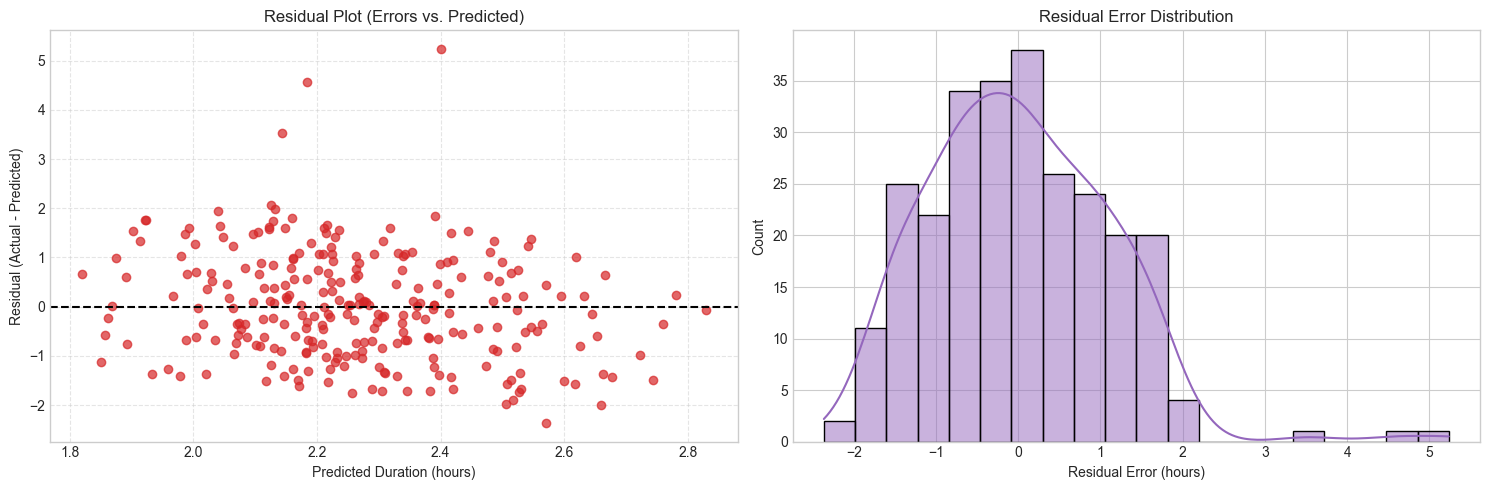

In [19]:
residuals = y_test - y_pred_lr

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Residual Scatter Plot
axes[0].scatter(y_pred_lr, residuals, alpha=0.7, color="#d62728")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[0].set_title("Residual Plot (Errors vs. Predicted)")
axes[0].set_xlabel("Predicted Duration (hours)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Residual Distribution Histogram
sns.histplot(residuals, kde=True, ax=axes[1], color="#9467bd", bins=20)
axes[1].set_title("Residual Error Distribution")
axes[1].set_xlabel("Residual Error (hours)")

plt.tight_layout()
plt.show()

## 19. Regression CoefficientsIn Linear Regression, the learned coefficients represent the expected change in charging duration (in hours) associated with a one-unit change in feature x_j, holding all other features constant.

In [20]:
coef_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Coefficient": model.coef_
})
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(by="Abs_Coefficient", ascending=False).drop(columns=["Abs_Coefficient"]).reset_index(drop=True)

print("=== LEARNED REGRESSION COEFFICIENTS ===")
print(coef_df.to_string(index=False))

=== LEARNED REGRESSION COEFFICIENTS ===
                                 Feature  Coefficient
                Vehicle Model_Chevy Bolt     0.213260
                      Day of Week_Sunday    -0.206645
                    Day of Week_Thursday     0.185110
               Vehicle Model_Nissan Leaf    -0.144228
                     Day of Week_Tuesday     0.131454
                    Vehicle Model_BMW i3    -0.092399
                        Temperature (°C)    -0.078936
        User Type_Long-Distance Traveler    -0.057354
               State of Charge (Start %)    -0.055255
                      Day of Week_Monday    -0.051877
                       Time of Day_Night     0.047495
                    Day of Week_Saturday    -0.047005
Distance Driven (since last charge) (km)     0.029959
                      User Type_Commuter     0.029031
                 User Type_Casual Driver     0.028323
              Vehicle Model_Hyundai Kona     0.028013
                     Time of Day_Evening  

## 20. Sample Predictions & Verification FunctionWe test a reusable prediction function with realistic sample inputs.

In [21]:
def predict_sample(sample_dict):
    df_sample = pd.DataFrame([sample_dict])
    transformed_sample = preprocessor.transform(df_sample)
    pred_hrs = float(model.predict(transformed_sample)[0])
    
    # Safety validation
    pred_hrs_valid = max(0.05, pred_hrs)
    
    tot_min = int(round(pred_hrs_valid * 60))
    h = tot_min // 60
    m = tot_min % 60
    fmt = f"{h}h {m}m" if h > 0 else f"{m}m"
    
    return pred_hrs_valid, fmt

sample_input_1 = {
    "Battery Capacity (kWh)": 75.0,
    "Energy Consumed (kWh)": 42.0,
    "Charging Rate (kW)": 11.0,
    "State of Charge (Start %)": 25.0,
    "State of Charge (End %)": 80.0,
    "Distance Driven (since last charge) (km)": 120.0,
    "Temperature (°C)": 27.0,
    "Vehicle Age (years)": 3.0,
    "Charger Type": "Level 2",
    "Vehicle Model": "Tesla Model 3",
    "Time of Day": "Afternoon",
    "Day of Week": "Monday",
    "User Type": "Commuter"
}

hrs, fmt_time = predict_sample(sample_input_1)
print(f"Sample Prediction 1 Output: {hrs:.2f} hours (≈ {fmt_time})")

Sample Prediction 1 Output: 2.24 hours (≈ 2h 14m)


## 21. ConclusionThe Linear Regression model was successfully trained to predict EV charging session duration using the selected charging and vehicle characteristics.Based on the empirical evaluation metrics obtained on the test dataset, the model performance was calculated and compared against the Mean Baseline model. Key features such as Energy Consumed, Charging Rate, and Starting SOC show strong associations with session duration. The project successfully demonstrates the application of fundamental supervised machine learning concepts for real-world EV charging duration estimation.

## 22. Future ScopeWhile the current Linear Regression baseline establishes a clean, interpretable model, several enhancements can be explored in future work:1. **Algorithm Comparison**: Evaluate non-linear regression algorithms (Decision Tree Regressor, Random Forest, Gradient Boosting) to capture potential complex non-linear interactions.2. **Expanded Dataset**: Train on larger, multi-year datasets spanning diverse geographical regions and charging networks.3. **Real-time Station Integration**: Incorporate real-time grid load, charger queuing status, and dynamic pricing APIs.4. **Weather API Integration**: Fetch live temperature, humidity, and weather conditions.5. **Telemetry & Mobile App**: Deploy model as a microservice endpoint for EV mobile app integration.